# TP3 - Regularization on the MLP (20 Newsgroups / TNG)
### Neural Networks / Deep Learning

Dataset: **20 Newsgroups** (TNG) — same as TP1/TP2.

## Objective
In TP2 the MLP **overfitted** (train_acc ~0.97, val_acc ~0.65, val_loss rising). Following the regularization lecture, add these as possible hyperparameters and study their effect:

- **L1 / L2 / L1+L2** regularization (penalty on the weights)
- **Dropout**
- **BatchNormalization**

For each one, following the class recommendations, look at:
- **absolute weight values** (do they shrink? does L1 give sparsity?)
- **training times**
- **learning-rate values**
- **noise in the learning curves**

and **justify the observed phenomena** with the lecture theory.

### Class recommendations used here (from `Regularización.pdf`)
- **L2 (Ridge):** keeps weights small → sigmoid/softmax works near its linear zone → less “overconfident” → less overfitting. `λ ≈ 1e-4` is a reasonable start; applied per layer, on the **weights only (not the bias)**.
- **L1 (LASSO):** shrinks all weights equally → **sparse** weights (many ≈ 0) → acts as feature selection.
- **L1+L2 (elastic net):** combination of both.
- **Dropout:** use **20–50 %**, on a **large** network; pairs well with a **higher learning rate + momentum**; makes the **train curve noisier** than validation.
- **BatchNorm:** fixes *internal covariate shift* → faster, more stable training, with a **mild regularizing** side effect; activation goes **after** BatchNorm, the dense layer uses **no bias** (BN's β is the bias), and it is **not usually combined with dropout**.

## 0. Setup

In [2]:
%pip install -q mlflow optuna
# If something is missing:
#   python -m pip install torch "numpy<2" nltk scikit-learn matplotlib tensorboard pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


/Users/stellaf.kirkvaag/anaconda3/envs/neural-networks/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/stellaf.kirkvaag/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/stellaf.kirkvaag/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/stellaf.kirkvaag/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     /Users/stellaf.kirkvaag/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/stellaf.kirkvaag/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 1. Data + preprocessing (reused from TP1/TP2)

Same pipeline as before. To keep the regularization comparison clean and fast, we **fix** the preprocessing / TF-IDF choices to the good values found in TP2 (stemming, stopword removal, unigrams) and vary only the regularization.

In [4]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))
class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Classes: {NUM_CLASSES} | Train: {len(newsgroups_train.data)} | Test: {len(newsgroups_test.data)}")

STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)


def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)

Classes: 20 | Train: 11314 | Test: 7532


In [5]:
# Fixed preprocessing (TP2 best) + TF-IDF. One train/val split reused by every experiment.
REMOVE_SW, NORM = True, "stem"
NGRAM, MAX_FEATURES, MIN_DF = (1, 1), 5000, 2

print("Preprocessing...")
train_proc = [preprocess_text(t, REMOVE_SW, NORM) for t in newsgroups_train.data]
test_proc  = [preprocess_text(t, REMOVE_SW, NORM) for t in newsgroups_test.data]

tr_texts, val_texts, tr_y, val_y = train_test_split(
    train_proc, newsgroups_train.target, test_size=0.2, random_state=SEED,
    stratify=newsgroups_train.target)

X_tr, X_val, vectorizer = vectorize_data(tr_texts, val_texts, NGRAM, MAX_FEATURES, MIN_DF)
INPUT_DIM = X_tr.shape[1]

train_loader = DataLoader(to_tensor_dataset(X_tr, tr_y), batch_size=64, shuffle=True)
val_loader = DataLoader(to_tensor_dataset(X_val, val_y), batch_size=64, shuffle=False)
print("Input dim (vocab):", INPUT_DIM)

Preprocessing...
Input dim (vocab): 5000


## 2. Model: MLP with optional BatchNorm

Same MLP as TP2 plus a `use_batchnorm` flag. Following the lecture, the block order is **Linear → BatchNorm → activation → (dropout)**, and when BatchNorm is on the dense layer uses **no bias** (BN's β plays that role). L1/L2 are applied as an explicit penalty on the loss (next section), so they are not part of the module.

In [6]:
ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid,
               "leaky_relu": nn.LeakyReLU, "elu": nn.ELU}


class MLP(nn.Module):
    def __init__(self, input_dim, num_classes, hidden_sizes,
                 activation="relu", dropout=0.0, use_batchnorm=False):
        super().__init__()
        act_cls = ACTIVATIONS[activation]
        layers = []
        prev = input_dim
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h, bias=not use_batchnorm))  # BN beta acts as the bias
            if use_batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(act_cls())                                   # activation AFTER BatchNorm
            if dropout and dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))                    # output logits
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

## 3. Training with L1/L2 penalty, timing, and weight inspection

`reg_penalty` adds the L1 and/or L2 term to the loss, computed **only over the Linear weight matrices** (not the biases, not the BatchNorm parameters) — exactly the class recommendation.

- **L2** adds `λ·Σ w²` → pushes weights uniformly small.
- **L1** adds `λ·Σ |w|` → drives many weights to exactly 0 (sparsity).

(We use an explicit penalty instead of the optimizer's `weight_decay` so we can do L1, L1+L2, and exclude the bias.)

In [7]:
def reg_penalty(model, l1=0.0, l2=0.0):
    pen = model.net[0].weight.new_zeros(())  # scalar on the right device
    for m in model.modules():
        if isinstance(m, nn.Linear):
            if l1:
                pen = pen + l1 * m.weight.abs().sum()
            if l2:
                pen = pen + l2 * m.weight.pow(2).sum()
    return pen


def all_weights(model):
    """Flat numpy array of every Linear weight (for the histograms)."""
    return np.concatenate([m.weight.detach().cpu().numpy().ravel()
                           for m in model.modules() if isinstance(m, nn.Linear)])


def train_mlp(model, train_loader, val_loader, optimizer, epochs,
              l1=0.0, l2=0.0, trial=None, run_name="mlp", verbose=False):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    t0 = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            base_loss = criterion(logits, yb)
            loss = base_loss + reg_penalty(model, l1, l2) if (l1 or l2) else base_loss
            loss.backward()
            optimizer.step()
            running_loss += base_loss.item() * xb.size(0)   # log the DATA loss only (fair comparison)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                running_loss += criterion(logits, yb).item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc);   history["val_acc"].append(val_acc)
        if verbose:
            print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
                  f"train_acc {train_acc:.4f} val_acc {val_acc:.4f} val_loss {val_loss:.4f}")
        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

    history["train_time"] = time.perf_counter() - t0
    return history

## 4. Controlled comparison: one technique at a time

We start from a **deliberately over-parameterized** network ([512, 256] hidden units) that overfits — the same situation as the end of TP2 — and apply **one regularizer at a time**, keeping everything else identical. This isolates each technique's effect (class rule: *don't change several hyperparameters at once*).

| Experiment | Change vs baseline |
|---|---|
| `baseline` | no regularization |
| `L2` | `λ_l2 = 1e-4` |
| `L1` | `λ_l1 = 1e-4` |
| `L1+L2` | both `1e-4` |
| `dropout` | `dropout = 0.5` |
| `batchnorm` | `use_batchnorm = True` |

In [ ]:
HIDDEN = [512, 256]
ACT = "relu"
LR = 1e-3
EPOCHS = 30

experiments = {
    "baseline":  dict(dropout=0.0, use_batchnorm=False, l1=0.0,  l2=0.0),
    "L2":        dict(dropout=0.0, use_batchnorm=False, l1=0.0,  l2=1e-4),
    "L1":        dict(dropout=0.0, use_batchnorm=False, l1=1e-4, l2=0.0),
    "L1+L2":     dict(dropout=0.0, use_batchnorm=False, l1=1e-4, l2=1e-4),
    "dropout":   dict(dropout=0.5, use_batchnorm=False, l1=0.0,  l2=0.0),
    "batchnorm": dict(dropout=0.0, use_batchnorm=True,  l1=0.0,  l2=0.0),
}

results = {}
for name, cfg in experiments.items():
    torch.manual_seed(SEED)  # same init every time -> fair comparison
    model = MLP(INPUT_DIM, NUM_CLASSES, HIDDEN, ACT,
                dropout=cfg["dropout"], use_batchnorm=cfg["use_batchnorm"])
    opt = optim.Adam(model.parameters(), lr=LR)
    hist = train_mlp(model, train_loader, val_loader, opt, EPOCHS,
                     l1=cfg["l1"], l2=cfg["l2"], run_name=name)
    results[name] = {"history": hist, "weights": all_weights(model)}
    print(f"{name:10s} | train_acc {hist['train_acc'][-1]:.3f} "
          f"| val_acc {hist['val_acc'][-1]:.3f} "
          f"| gap {hist['train_acc'][-1]-hist['val_acc'][-1]:.3f} "
          f"| time {hist['train_time']:.1f}s")

In [12]:
# Summary table: performance, generalization gap, weight magnitude, sparsity, training time
rows = []
for name, r in results.items():
    h, w = r["history"], r["weights"]
    rows.append({
        "experiment": name,
        "train_acc": round(h["train_acc"][-1], 4),
        "val_acc": round(h["val_acc"][-1], 4),
        "gap": round(h["train_acc"][-1] - h["val_acc"][-1], 4),
        "mean_abs_w": round(float(np.abs(w).mean()), 5),
        "pct_w_near_0": round(float((np.abs(w) < 1e-3).mean()) * 100, 1),   # sparsity (%)
        "train_time_s": round(h["train_time"], 1),
    })
summary = pd.DataFrame(rows).set_index("experiment")
summary

,train_acc,val_acc,gap,mean_abs_w,pct_w_near_0,train_time_s
experiment,,,,,,
baseline,0.9707,0.6633,0.3074,0.04458,1.4,137.5
L2,0.9685,0.6430,0.3256,0.01584,20.7,198.8
L1,0.0508,0.0530,-0.0022,0.00012,100.0,220.5
L1+L2,0.0514,0.0530,-0.0017,0.00012,100.0,262.5
dropout,0.9718,0.6734,0.2984,0.04963,1.3,167.0
batchnorm,0.9715,0.6836,0.2879,0.01497,4.4,178.9


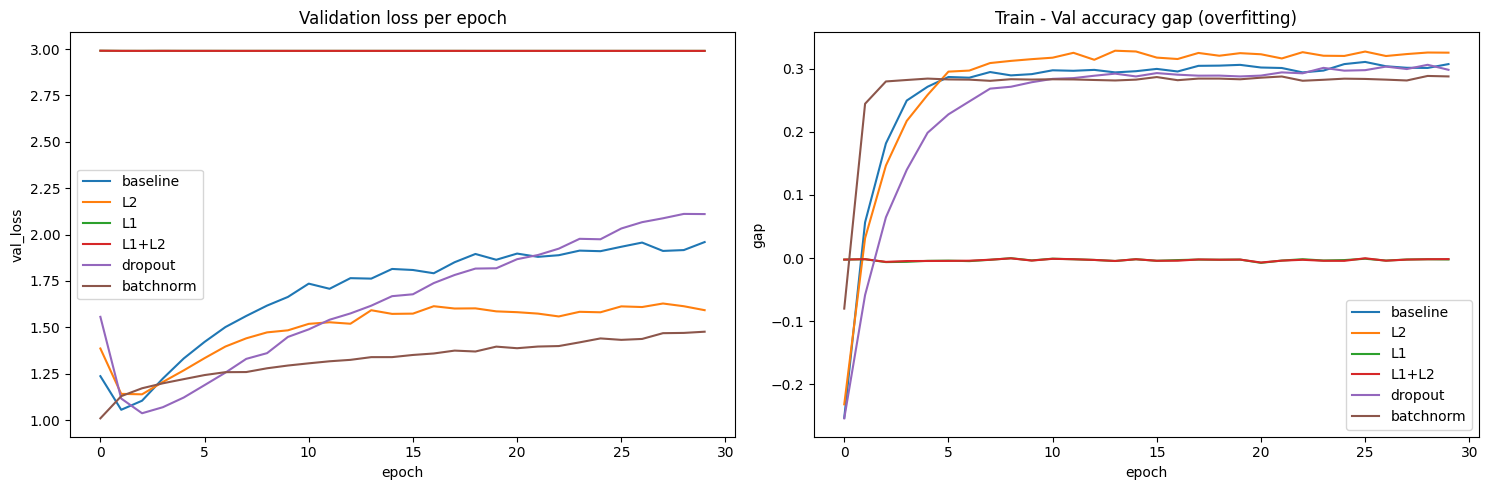

In [13]:
# Learning curves: val_loss (noise / overfitting) and the train-vs-val accuracy gap
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, r in results.items():
    h = r["history"]
    axes[0].plot(h["val_loss"], label=name)
    axes[1].plot(np.array(h["train_acc"]) - np.array(h["val_acc"]), label=name)
axes[0].set_title("Validation loss per epoch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("val_loss"); axes[0].legend()
axes[1].set_title("Train - Val accuracy gap (overfitting)"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("gap"); axes[1].legend()
plt.tight_layout(); plt.show()

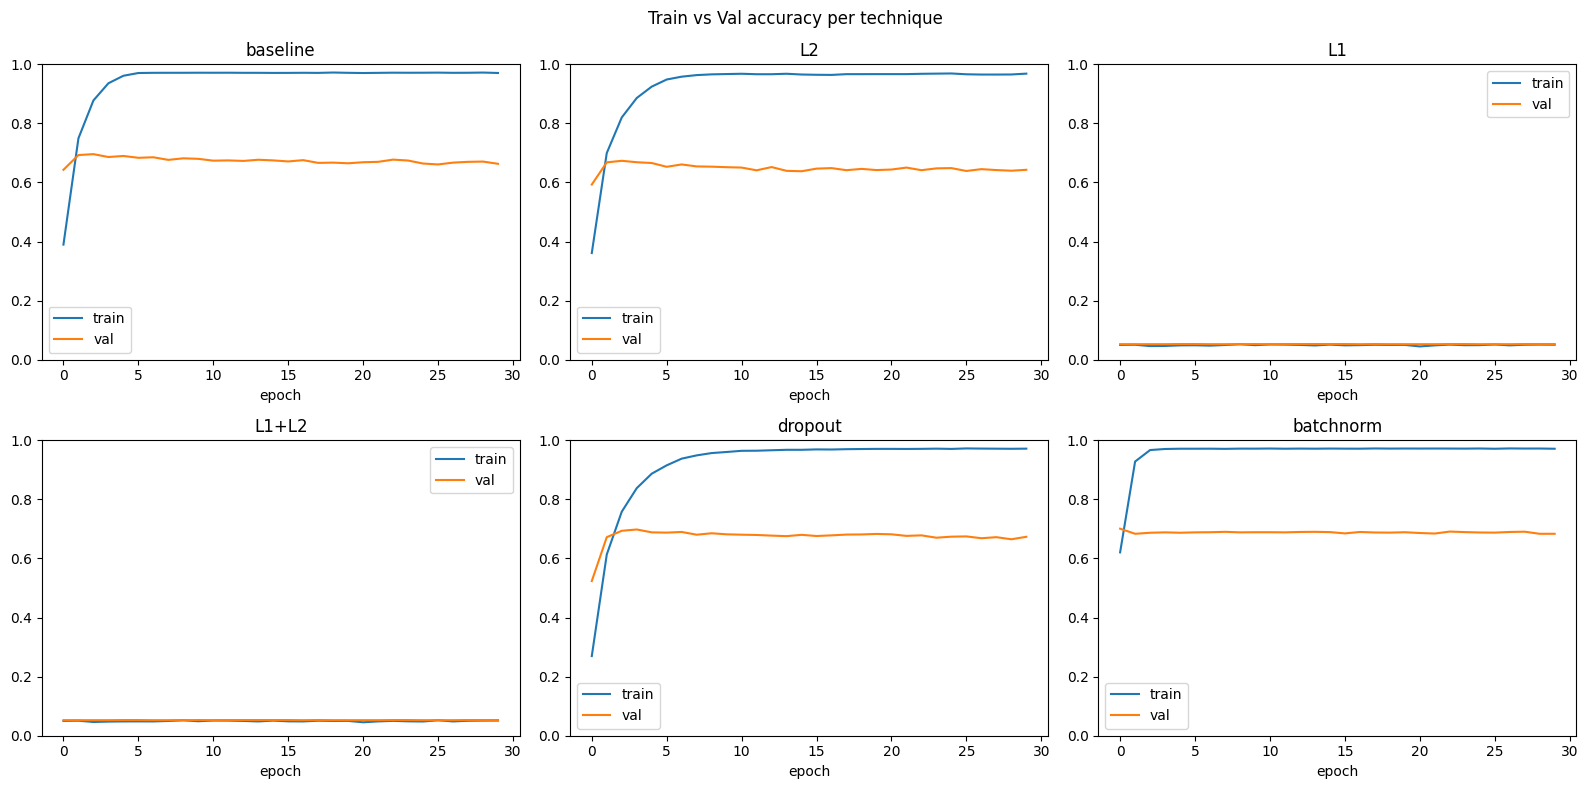

In [14]:
# Per-technique train vs val accuracy (to see the NOISE in the curves)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (name, r) in zip(axes.ravel(), results.items()):
    h = r["history"]
    ax.plot(h["train_acc"], label="train")
    ax.plot(h["val_acc"], label="val")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylim(0, 1); ax.legend()
plt.suptitle("Train vs Val accuracy per technique")
plt.tight_layout(); plt.show()

#### Results and learning curves

The MLP uses TF-IDF features to classify 20 Newsgroups posts into 20 topics. I compared the regularization methods to see whether they helped the model classify unseen posts.

The baseline reached **97.07% training accuracy** and **66.33% validation accuracy**. Training accuracy rose quickly, while validation accuracy levelled off and validation loss rose after the first few epochs. This suggests overfitting.

BatchNorm reached high training accuracy earlier and finished with the highest validation accuracy (**68.36%**), followed by dropout (**67.34%**). Both had slightly smaller measured train–validation gaps, although validation loss still rose with BatchNorm. L2 finished with lower validation accuracy (**64.30%**) but lower validation loss than the baseline. Accuracy measures how often the model picks the right topic, while loss also considers the probability it assigns to that topic.

For the dropout comparison, I kept Adam and the learning rate of 0.001 the same as in the baseline so dropout was the only change. A higher learning rate, momentum, and a max-norm constraint are possible follow-up experiments based on the lecture.

### Follow-up experiment: Weaker L1 penalties

In the original comparison, L1 with λ = 1e-4 reduced validation accuracy to 5.3%, close to chance. Nearly all weights fell below |w| < 0.001, and the model showed severe underfitting.

I test two weaker penalties, λ = 1e-6 and λ = 1e-5, using the same data split, model, seed, optimizer, and training settings. I compare the results with the baseline and the original L1 run to see whether a weaker penalty produces more near-zero weights while preserving validation performance.

In [9]:
l1_rows = []

for l1_strength in (1e-6, 1e-5):
    name = f"L1 ({l1_strength:g})"
    torch.manual_seed(SEED)

    l1_model = MLP(
        INPUT_DIM, NUM_CLASSES, [512, 256], "relu",
        dropout=0.0, use_batchnorm=False,
    )
    l1_opt = optim.Adam(l1_model.parameters(), lr=1e-3)
    l1_hist = train_mlp(
        l1_model, train_loader, val_loader, l1_opt, 30,
        l1=l1_strength, l2=0.0, run_name=name,
    )

    abs_weights = np.abs(all_weights(l1_model))
    train_acc = l1_hist["train_acc"][-1]
    val_acc = l1_hist["val_acc"][-1]

    l1_rows.append({
        "experiment": name,
        "train_acc": round(train_acc, 4),
        "val_acc": round(val_acc, 4),
        "gap": round(train_acc - val_acc, 4),
        "mean_abs_w": round(float(abs_weights.mean()), 5),
        "pct_w_near_0": round(float((abs_weights < 1e-3).mean()) * 100, 1),
        "train_time_s": round(l1_hist["train_time"], 1),
    })
    print(f"{name} | val_acc {val_acc:.3f} | time {l1_hist['train_time']:.1f}s")

l1_summary = pd.DataFrame(l1_rows).set_index("experiment")
l1_summary

L1 (1e-06) | val_acc 0.630 | time 185.1s
L1 (1e-05) | val_acc 0.627 | time 162.6s


,train_acc,val_acc,gap,mean_abs_w,pct_w_near_0,train_time_s
experiment,,,,,,
L1 (1e-06),0.9714,0.6297,0.3417,0.02509,38.5,185.1
L1 (1e-05),0.9698,0.6270,0.3428,0.00995,66.3,162.6


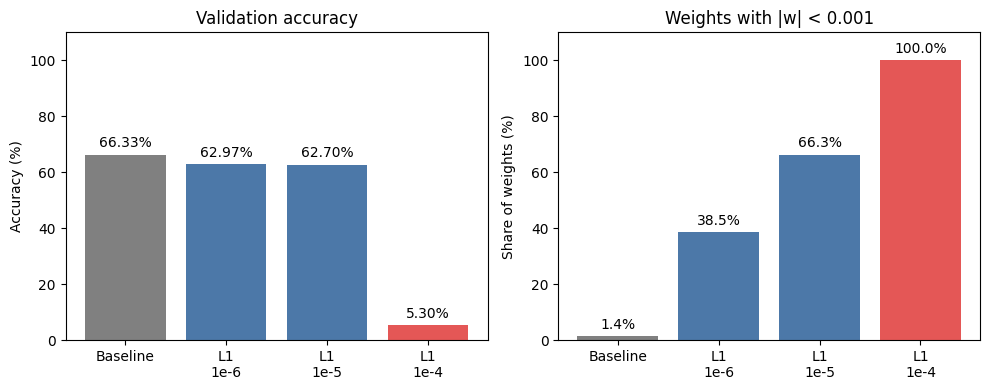

In [10]:
import matplotlib.pyplot as plt

experiments = ["Baseline", "L1\n1e-6", "L1\n1e-5", "L1\n1e-4"]
validation_accuracy = [66.33, 62.97, 62.70, 5.30]
near_zero_weights = [1.4, 38.5, 66.3, 100.0]
colors = ["#808080", "#4c78a8", "#4c78a8", "#e45756"]

fig, (ax_acc, ax_weights) = plt.subplots(1, 2, figsize=(10, 4))

accuracy_bars = ax_acc.bar(experiments, validation_accuracy, color=colors)
ax_acc.set_title("Validation accuracy")
ax_acc.set_ylabel("Accuracy (%)")
ax_acc.bar_label(accuracy_bars, fmt="%.2f%%", padding=3)

weight_bars = ax_weights.bar(experiments, near_zero_weights, color=colors)
ax_weights.set_title("Weights with |w| < 0.001")
ax_weights.set_ylabel("Share of weights (%)")
ax_weights.bar_label(weight_bars, fmt="%.1f%%", padding=3)

for axis in (ax_acc, ax_weights):
    axis.set_ylim(0, 110)
    axis.set_yticks(range(0, 101, 20))

plt.tight_layout()
plt.show()


#### Analysis

In the original L1 run, `λ = 1e-4` pushed nearly all weights below `|w| < 0.001`. Training and validation accuracy stayed near **5%**, close to chance across the 20 topics. This indicates severe underfitting. I tested weaker penalties to see whether the model could still distinguish topics while keeping many weights near zero.

Validation accuracy recovered to **62.97%** at `λ = 1e-6` and **62.70%** at `λ = 1e-5`. Between these settings, the share of near-zero weights rose from **38.5% to 66.3%**, while accuracy fell by **0.27 percentage points**. Both runs scored below the baseline. With one run per setting, it is unclear whether the small difference between the two weaker penalties would persist across seeds.

## 5. Absolute weight values (histograms)

These histograms show the absolute weight values for each method. **L1 can push many weights close to zero**. A tall first bin indicates many small weights within that bin's range. The log y-axis makes it easier to see bins with very different counts.

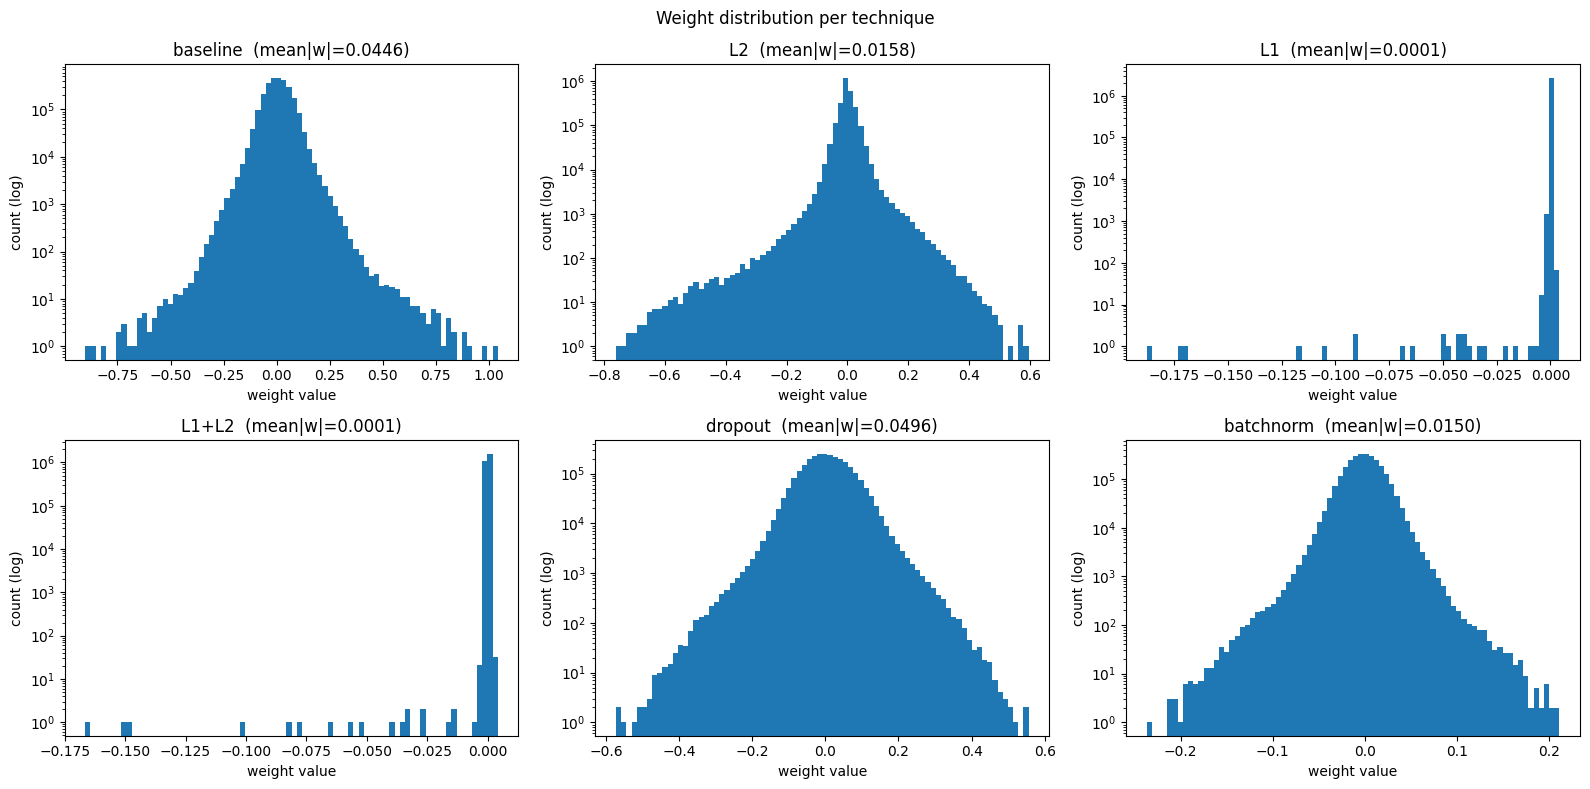

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (name, r) in zip(axes.ravel(), results.items()):
    ax.hist(r["weights"], bins=80, log=True)
    ax.set_title(f"{name}  (mean|w|={np.abs(r['weights']).mean():.4f})")
    ax.set_xlabel("weight value"); ax.set_ylabel("count (log)")
plt.suptitle("Weight distribution per technique")
plt.tight_layout(); plt.show()

#### Absolute weight values

L2 reduced the mean absolute weight from **0.04458 to 0.01584**, consistent with weight shrinkage. The original L1 histogram shows the run at `λ = 1e-4`, where almost all weights fell below `|w| < 0.001` and the model underfit. Section 4 shows what happened with weaker penalties. The histograms combine weights from all layers, so the first layer contributes most of the values. BatchNorm changes how the scale of the weights affects the activations, which limits what we can infer from its smaller average weights.

#### Training time and noise

In these CPU runs, the baseline took **137.5 s**, dropout took **167.0 s**, and BatchNorm took **178.9 s**. With one timing per setting, I treat these as approximate comparisons. Dropout randomly masks activations, and BatchNorm uses statistics that vary across batches. The plots show some fluctuations, but a comparison of curve noise would require measuring those fluctuations over the same epochs and repeating the runs. Training accuracy was measured with dropout active, while validation accuracy was measured with dropout off.

## 6. BatchNorm at a higher learning rate

The lecture suggests that BatchNorm can help when using a higher learning rate. I compare the baseline and the BatchNorm model at 0.01, ten times the learning rate used in Section 4.

baseline @1e-2   | best val_acc 0.683 | final val_loss 3.066
batchnorm @1e-2  | best val_acc 0.683 | final val_loss 2.519


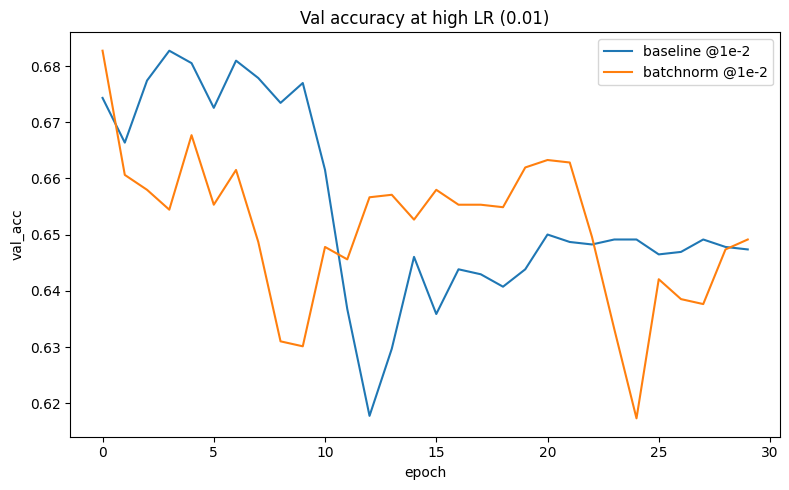

In [16]:
HIGH_LR = 1e-2
lr_results = {}
for name, use_bn in [("baseline @1e-2", False), ("batchnorm @1e-2", True)]:
    torch.manual_seed(SEED)
    model = MLP(INPUT_DIM, NUM_CLASSES, HIDDEN, ACT, dropout=0.0, use_batchnorm=use_bn)
    opt = optim.Adam(model.parameters(), lr=HIGH_LR)
    hist = train_mlp(model, train_loader, val_loader, opt, EPOCHS, run_name=name)
    lr_results[name] = hist
    print(f"{name:16s} | best val_acc {max(hist['val_acc']):.3f} | final val_loss {hist['val_loss'][-1]:.3f}")

plt.figure(figsize=(8, 5))
for name, h in lr_results.items():
    plt.plot(h["val_acc"], label=name)
plt.title(f"Val accuracy at high LR ({HIGH_LR})"); plt.xlabel("epoch"); plt.ylabel("val_acc"); plt.legend()
plt.tight_layout(); plt.show()

**Learning rate and BatchNorm**

At lr = 0.01, both models peaked at around 68.3% validation accuracy. BatchNorm ended with a lower validation loss (2.52 vs. 3.07), but its validation accuracy also dipped to about 61.7%. The lower final loss shows a difference at the end of training. Stability depends on how the curves behave throughout the run. To separate faster learning from a possible regularizing effect, I would compare the time to reach a shared validation target and the validation performance at similar training accuracy, across several learning rates and seeds.

## 7. Optuna search including the regularization hyperparameters

Now we let Optuna search over the regularization choices **together** with the training hyperparameters, with a `MedianPruner`. The search picks the regularization type and strength, dropout, and whether to use BatchNorm.

In [17]:
EPOCHS_SEARCH = 12
N_TRIALS = 25


def objective(trial):
    n_layers = trial.suggest_int("n_layers", 1, 2)
    hidden = [trial.suggest_categorical(f"units_l{i}", [128, 256, 512]) for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", ["relu", "leaky_relu", "tanh"])
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    optimizer_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop"])

    # --- regularization hyperparameters (the point of TP3) ---
    reg_type = trial.suggest_categorical("reg_type", ["none", "l1", "l2", "l1_l2"])
    reg_lambda = trial.suggest_float("reg_lambda", 1e-6, 1e-2, log=True) if reg_type != "none" else 0.0
    l1 = reg_lambda if reg_type in ("l1", "l1_l2") else 0.0
    l2 = reg_lambda if reg_type in ("l2", "l1_l2") else 0.0
    use_bn = trial.suggest_categorical("use_batchnorm", [False, True])
    # lecture: BN is not usually combined with dropout -> only use dropout when BN is off
    dropout = 0.0 if use_bn else trial.suggest_float("dropout", 0.0, 0.5)

    torch.manual_seed(SEED)
    model = MLP(INPUT_DIM, NUM_CLASSES, hidden, activation, dropout=dropout, use_batchnorm=use_bn)
    opt = (optim.Adam if optimizer_name == "adam" else optim.RMSprop)(model.parameters(), lr=lr)
    hist = train_mlp(model, train_loader, val_loader, opt, EPOCHS_SEARCH,
                     l1=l1, l2=l2, trial=trial, run_name=f"trial_{trial.number}")
    trial.set_user_attr("train_time", hist["train_time"])
    return max(hist["val_acc"])   # best epoch (early-stopping-like)


pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3)
study = optuna.create_study(direction="maximize", pruner=pruner,
                            sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS)
print("\nBest params:", study.best_params)
print("Best val accuracy:", round(study.best_value, 4))

[I 2026-11-02 15:23:54,170] A new study created in memory with name: no-name-5a4574d6-1c6d-46be-b987-1f2a395c66ce
[I 2026-11-02 15:24:17,890] Trial 0 finished with value: 0.6942112240388865 and parameters: {'n_layers': 1, 'units_l0': 128, 'activation': 'relu', 'lr': 0.005399484409787433, 'optimizer': 'rmsprop', 'reg_type': 'l1', 'reg_lambda': 5.337032762603957e-06, 'use_batchnorm': True}. Best is trial 0 with value: 0.6942112240388865.
[I 2026-11-02 15:25:53,406] Trial 1 finished with value: 0.05302695536897923 and parameters: {'n_layers': 2, 'units_l0': 512, 'units_l1': 512, 'activation': 'leaky_relu', 'lr': 0.0010677482709481358, 'optimizer': 'adam', 'reg_type': 'l1_l2', 'reg_lambda': 0.007286653737491046, 'use_batchnorm': False, 'dropout': 0.048836057003191935}. Best is trial 0 with value: 0.6942112240388865.
[I 2026-11-02 15:27:21,956] Trial 2 finished with value: 0.6345558992487847 and parameters: {'n_layers': 2, 'units_l0': 512, 'units_l1': 256, 'activation': 'relu', 'lr': 0.0012


Best params: {'n_layers': 1, 'units_l0': 256, 'activation': 'relu', 'lr': 0.001217284708112243, 'optimizer': 'rmsprop', 'reg_type': 'l1', 'reg_lambda': 1.0521761868451139e-06, 'use_batchnorm': False, 'dropout': 0.36450358402049365}
Best val accuracy: 0.7296


In [18]:
df = study.trials_dataframe()
df["train_time"] = [t.user_attrs.get("train_time", np.nan) for t in study.trials]
print("Trials:", len(df), "| COMPLETE:", (df['state']=='COMPLETE').sum(), "| PRUNED:", (df['state']=='PRUNED').sum())
cols = [c for c in ["number", "value", "train_time", "state", "params_reg_type",
                     "params_reg_lambda", "params_use_batchnorm", "params_dropout"] if c in df.columns]
df[cols].sort_values("value", ascending=False, na_position="last").head(10)

Trials: 25 | COMPLETE: 18 | PRUNED: 7


,number,value,train_time,state,params_reg_type,params_reg_lambda,params_use_batchnorm,params_dropout
3,3,0.729563,41.900049,COMPLETE,l1,0.000001,False,0.364504
10,10,0.728679,24.209160,COMPLETE,none,NaN,False,0.487231
19,19,0.726911,22.691064,COMPLETE,none,NaN,False,0.335672
13,13,0.726911,34.031604,COMPLETE,none,NaN,False,0.379871
22,22,0.726469,29.083293,COMPLETE,none,NaN,False,0.368026
16,16,0.724260,31.400046,COMPLETE,l2,0.000071,False,0.285735
23,23,0.718957,33.495945,COMPLETE,none,NaN,False,0.239954
7,7,0.707910,76.618965,COMPLETE,l1_l2,0.000009,True,NaN
14,14,0.699514,58.654971,COMPLETE,l2,0.001030,False,0.396321
21,21,0.698188,39.519906,COMPLETE,l1,0.000032,False,0.371943


**Optuna results**

I used Optuna to see which combination of regularization and training settings helped the MLP classify unseen Newsgroups posts. The best trial reached 72.96% validation accuracy with one hidden layer of 256 units, ReLU, RMSProp, 36% dropout, and a weak L1 penalty of about 1e-6. It ran without BatchNorm.

The weak L1 penalty is worth noting. In Section 4, the strongest L1 penalty gave near-chance accuracy, while weaker penalties let the model learn again. The Optuna result shows that a weak L1 penalty can be part of a well-performing configuration. Since the search changed several settings at once, I would repeat the winning trial with dropout set to zero to see how much dropout contributed.

## 8. Final model on the test set

Train the best configuration on the full training set and evaluate on the real test set, comparing to the earlier baselines: **softmax (TP1) = 0.6626** and **unregularized MLP (TP2) = 0.6516**.

In [20]:
SOFTMAX_TP1 = 0.6626
MLP_TP2 = 0.6516
best = study.best_params

# rebuild config from best params
b_hidden = [best[f"units_l{i}"] for i in range(best["n_layers"])]
b_use_bn = best["use_batchnorm"]
b_dropout = 0.0 if b_use_bn else best.get("dropout", 0.0)
b_rtype = best["reg_type"]
b_lam = best.get("reg_lambda", 0.0)
b_l1 = b_lam if b_rtype in ("l1", "l1_l2") else 0.0
b_l2 = b_lam if b_rtype in ("l2", "l1_l2") else 0.0

MAX_EPOCHS = 15

# STEP 1 - choose the number of epochs on the VALIDATION split (reuse section-4/7 loaders).
#          The test set is NOT touched here, so there is no model selection on test.
torch.manual_seed(SEED)
sel_model = MLP(X_tr.shape[1], NUM_CLASSES, b_hidden, best["activation"],
                dropout=b_dropout, use_batchnorm=b_use_bn)
sel_opt = (optim.Adam if best["optimizer"] == "adam" else optim.RMSprop)(sel_model.parameters(), lr=best["lr"])
sel_hist = train_mlp(sel_model, train_loader, val_loader, sel_opt, epochs=MAX_EPOCHS,
                     l1=b_l1, l2=b_l2, run_name="select")
chosen_epochs = int(np.argmax(sel_hist["val_acc"])) + 1
print(f"Epochs chosen on validation: {chosen_epochs} (val_acc {max(sel_hist['val_acc']):.4f})")

# STEP 2 - retrain on the FULL training set for that many epochs, then evaluate ONCE on test.
X_train_full, X_test_full, _ = vectorize_data(train_proc, test_proc, NGRAM, MAX_FEATURES, MIN_DF)
full_train_loader = DataLoader(to_tensor_dataset(X_train_full, newsgroups_train.target), batch_size=64, shuffle=True)
test_loader = DataLoader(to_tensor_dataset(X_test_full, newsgroups_test.target), batch_size=64, shuffle=False)

torch.manual_seed(SEED)
final_model = MLP(X_train_full.shape[1], NUM_CLASSES, b_hidden, best["activation"],
                  dropout=b_dropout, use_batchnorm=b_use_bn)
opt = (optim.Adam if best["optimizer"] == "adam" else optim.RMSprop)(final_model.parameters(), lr=best["lr"])
final_hist = train_mlp(final_model, full_train_loader, test_loader, opt, epochs=chosen_epochs,
                       l1=b_l1, l2=b_l2, run_name="final", verbose=True)

# The epoch count was fixed on validation, so we report the LAST epoch's test accuracy (no test selection).
final_test_acc = final_hist["val_acc"][-1]
print(f"\nFinal test accuracy (epochs fixed on validation = {chosen_epochs}): {final_test_acc:.4f}")
print(f"MLP without regularization (TP2):                        {MLP_TP2:.4f}")
print(f"Softmax (TP1):                                           {SOFTMAX_TP1:.4f}")

Epochs chosen on validation: 5 (val_acc 0.7296)
[final] Epoch 1/5 - train_acc 0.5618 val_acc 0.6434 val_loss 1.4039
[final] Epoch 2/5 - train_acc 0.7493 val_acc 0.6585 val_loss 1.1828
[final] Epoch 3/5 - train_acc 0.8041 val_acc 0.6654 val_loss 1.1230
[final] Epoch 4/5 - train_acc 0.8458 val_acc 0.6709 val_loss 1.1092
[final] Epoch 5/5 - train_acc 0.8730 val_acc 0.6693 val_loss 1.1228

Final test accuracy (epochs fixed on validation = 5): 0.6693
MLP without regularization (TP2):                        0.6516
Softmax (TP1):                                           0.6626


#### Final test result

I used validation accuracy to choose **five training epochs**, then retrained the selected model on the full training set. The notebook measured test accuracy after each epoch. At epoch 5, which I had selected in advance, the model correctly classified **66.93%** of the test posts.

This was slightly above the original TP1 softmax result (**66.26%**) and the TP2 MLP result (**65.16%**), and slightly below the revised TP1 result (**67.66%**). The assignments used different preprocessing and training settings, so I use these scores as reference points. Section 4 provides a more direct comparison of the regularization methods.

#### Conclusion

The goal was to see whether regularization helps an MLP that already performs well on training data classify **unseen 20 Newsgroups posts**. The clearest lesson was how much the strength of the penalty matters. Strong L1 pushed almost all weights near zero and brought accuracy down to chance. Weaker L1 kept many weights near zero while allowing the model to distinguish topics, though both settings scored below the baseline on validation. L2 also reduced weight magnitudes without improving validation accuracy. In these runs, smaller weights alone were a poor indicator of better generalization.

Dropout and BatchNorm gave slightly higher validation accuracy in the controlled comparison. BatchNorm also reached high training accuracy earlier. At the higher learning rate, it achieved a lower final validation loss, but both models reached about the same peak accuracy. I would repeat the comparison with different random seeds to see whether dropout and BatchNorm consistently improve validation accuracy. What I learned from this assignment is to judge regularization by looking at **validation performance, the shape of the learning curves, weight magnitudes, and training cost together**. A smaller train–validation gap can even be a sign that the model learned less, as the strongest L1 run showed.

## AI-use statement

I used ChatGPT and Codex to clarify regularization concepts and help write the code for the two L1 experiments and the figure. I also used them to test my understanding, question my reasoning, and consider other explanations for what I saw in the learning curves.

I ran both L1 experiments in VS Code and compared their validation accuracy and near-zero weights with the original results. I used those comparisons to explain why the strongest penalty led to underfitting and what changed when I lowered it. AI also helped me write parts of my answers and express my reasoning more clearly in English.